# Experiment analysis (section f)

Reads only the raw CSV files written by `experiments/benchmark.py` into `results/`, and writes every
figure to `results/figures/` and every table to `results/tables/`. Nothing here is edited by hand.

Averages use reachable start–goal pairs only; unreachable pairs are counted separately.
Every number is the mean ± standard deviation across the seeded pairs of one configuration.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
TABLES = RESULTS / "tables"
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)

raw = {path.stem: pd.read_csv(path) for path in sorted(RESULTS.glob("sweep*.csv"))}
for name, frame in raw.items():
    print(f"{name:32} {len(frame):5} rows, {frame.reachable.eq(False).sum() // frame.planner.nunique():3} unreachable pairs")

sweep1_grid_size                  1000 rows,   0 unreachable pairs
sweep2_obstacle_density           1000 rows,  39 unreachable pairs
sweep3_heuristic_connectivity      400 rows,   0 unreachable pairs
sweep4_weight                      300 rows,   1 unreachable pairs
sweep5_map_terrain                 400 rows,   2 unreachable pairs


In [2]:
PLANNER_LABEL = {
    "dijkstra": "Dijkstra",
    "astar": "A* (Octile)",
    "greedy": "Greedy Best-First",
    "weighted_astar_w2": "Weighted A* (w = 2)",
}
PLANNER_COLOUR = {
    "dijkstra": "#2a78d6",
    "astar": "#eb6834",
    "greedy": "#1baf7a",
    "weighted_astar_w2": "#eda100",
}
PLANNER_MARKER = {"dijkstra": "o", "astar": "s", "greedy": "^", "weighted_astar_w2": "D"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 7,
})


def reachable(frame):
    return frame[frame.reachable]


def summarise(frame, by, metrics=("expanded", "runtime_ms", "path_cost", "peak_memory", "suboptimality_ratio")):
    grouped = reachable(frame).groupby(list(by))
    table = grouped[list(metrics)].agg(["mean", "std"])
    table["pairs"] = grouped.size()
    return table


def mean_std(table, metric, digits=1):
    return table[(metric, "mean")].round(digits).astype(str) + " ± " + table[(metric, "std")].round(digits).astype(str)


LABEL_NUDGE = {"greedy": -7, "weighted_astar_w2": 7}


def label_line_end(ax, x, y, text, nudge=0):
    ax.annotate(text, (x, y), xytext=(6, nudge), textcoords="offset points", va="center", color=INK, fontsize=9)

## Sweep 1: grid size

/var/folders/1z/p8dptcb57h9_93kfys692jn80000gn/T/ipykernel_9073/3909987876.py:32: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  table["pairs"] = grouped.size()


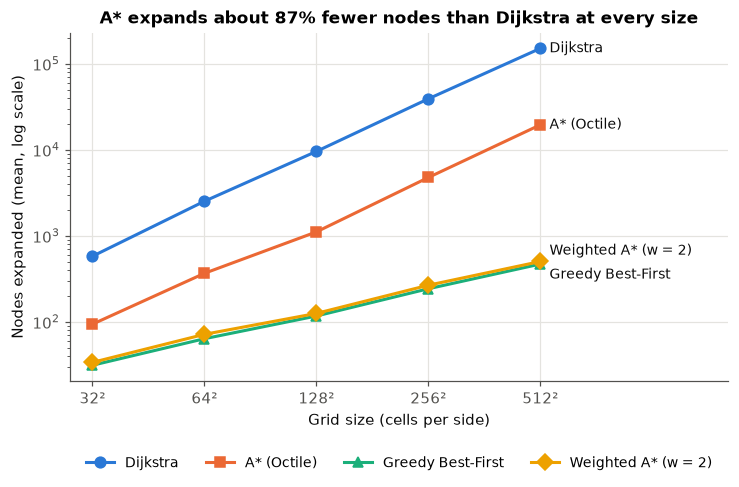

A* node saving vs Dijkstra (%): {32: 83.8, 64: 85.5, 128: 88.4, 256: 87.8, 512: 87.1}
A* speed-up vs Dijkstra (x): {32: 5.1, 64: 5.8, 128: 7.2, 256: 7.0, 512: 7.0}


In [3]:
s1 = raw["sweep1_grid_size"]
t1 = summarise(s1, ["grid_size", "planner"])
fig, ax = plt.subplots(figsize=(7, 4.6))
for planner in PLANNER_LABEL:
    rows = t1.xs(planner, level="planner")
    ax.plot(rows.index, rows[("expanded", "mean")], marker=PLANNER_MARKER[planner], color=PLANNER_COLOUR[planner],
            label=PLANNER_LABEL[planner])
    label_line_end(ax, rows.index[-1], rows[("expanded", "mean")].iloc[-1], PLANNER_LABEL[planner], LABEL_NUDGE.get(planner, 0))
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(sorted(s1.grid_size.unique()), [f"{n}²" for n in sorted(s1.grid_size.unique())])
ax.set_xlim(right=s1.grid_size.max() * 3.2)
ax.set_xlabel("Grid size (cells per side)")
ax.set_ylabel("Nodes expanded (mean, log scale)")
ax.set_title("A* expands about 87% fewer nodes than Dijkstra at every size")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "fig_sweep1_nodes_vs_size.png")
plt.show()

wide = t1[("expanded", "mean")].unstack("planner")
saving = (1 - wide["astar"] / wide["dijkstra"]) * 100
speed = t1[("runtime_ms", "mean")].unstack("planner")
print("A* node saving vs Dijkstra (%):", saving.round(1).to_dict())
print("A* speed-up vs Dijkstra (x):", (speed["dijkstra"] / speed["astar"]).round(1).to_dict())

## Sweep 2: obstacle density

/var/folders/1z/p8dptcb57h9_93kfys692jn80000gn/T/ipykernel_9073/3909987876.py:32: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  table["pairs"] = grouped.size()


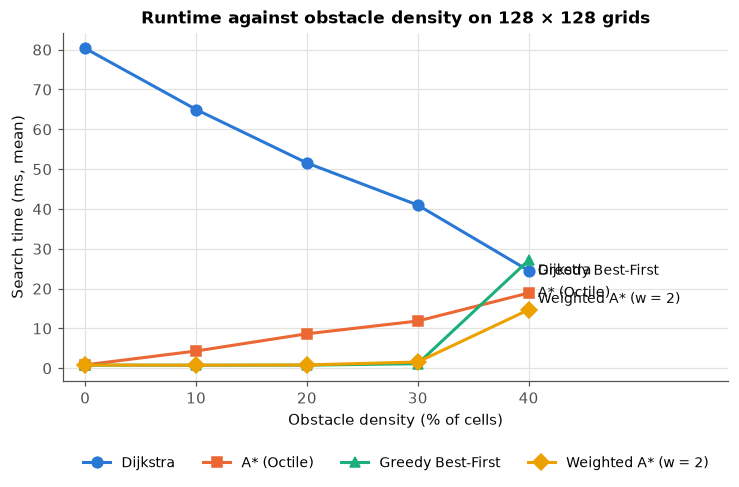

Unreachable pairs per density: {0.3: 3, 0.4: 36}
A* node saving vs Dijkstra by density (%): {0.0: 99.2, 0.1: 94.6, 0.2: 86.1, 0.3: 75.1, 0.4: 30.7}


In [4]:
s2 = raw["sweep2_obstacle_density"]
t2 = summarise(s2, ["obstacle_density", "planner"])
fig, ax = plt.subplots(figsize=(7, 4.6))
for planner in PLANNER_LABEL:
    rows = t2.xs(planner, level="planner")
    x = rows.index * 100
    ax.plot(x, rows[("runtime_ms", "mean")], marker=PLANNER_MARKER[planner], color=PLANNER_COLOUR[planner],
            label=PLANNER_LABEL[planner])
    label_line_end(ax, x[-1], rows[("runtime_ms", "mean")].iloc[-1], PLANNER_LABEL[planner], LABEL_NUDGE.get(planner, 0))
ax.set_xticks(sorted(s2.obstacle_density.unique() * 100))
ax.set_xlim(right=58)
ax.set_xlabel("Obstacle density (% of cells)")
ax.set_ylabel("Search time (ms, mean)")
ax.set_title("Runtime against obstacle density on 128 × 128 grids")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "fig_sweep2_runtime_vs_density.png")
plt.show()

unreach2 = s2[~s2.reachable].groupby("obstacle_density").pair_id.nunique()
print("Unreachable pairs per density:", unreach2.to_dict())
wide2 = t2[("expanded", "mean")].unstack("planner")
print("A* node saving vs Dijkstra by density (%):", ((1 - wide2["astar"] / wide2["dijkstra"]) * 100).round(1).to_dict())

## Sweep 3: heuristic and connectivity

/var/folders/1z/p8dptcb57h9_93kfys692jn80000gn/T/ipykernel_9073/3909987876.py:32: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  table["pairs"] = grouped.size()


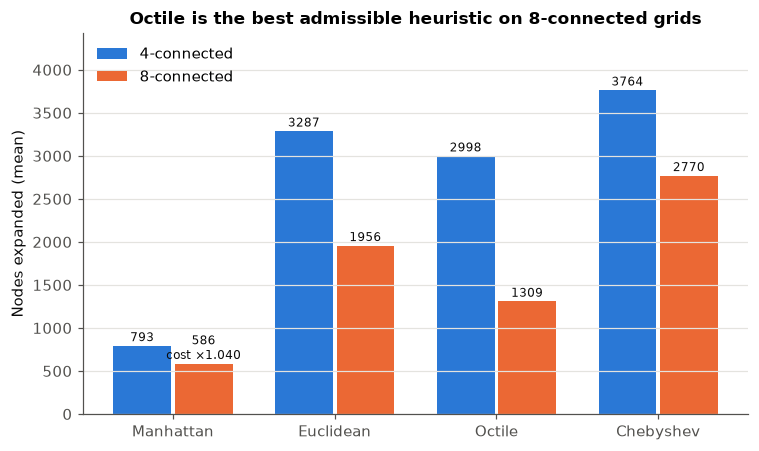

In [5]:
s3 = raw["sweep3_heuristic_connectivity"]
t3 = summarise(s3, ["heuristic", "connectivity"])
order = ["manhattan", "euclidean", "octile", "chebyshev"]
fig, ax = plt.subplots(figsize=(7, 4.2))
width = 0.38
for i, (connectivity, colour) in enumerate([(4, "#2a78d6"), (8, "#eb6834")]):
    means = [t3.loc[(h, connectivity), ("expanded", "mean")] for h in order]
    xs = np.arange(len(order)) + (i - 0.5) * width
    bars = ax.bar(xs, means, width * 0.94, color=colour, label=f"{connectivity}-connected")
    for x, h, m in zip(xs, order, means):
        ratio = t3.loc[(h, connectivity), ("suboptimality_ratio", "mean")]
        note = f"{m:.0f}" + (f"\ncost ×{ratio:.3f}" if ratio > 1.0005 else "")
        ax.annotate(note, (x, m), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xticks(range(len(order)), [h.capitalize() for h in order])
ax.set_ylabel("Nodes expanded (mean)")
ax.set_title("Octile is the best admissible heuristic on 8-connected grids")
ax.set_ylim(top=ax.get_ylim()[1] * 1.12)
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "fig_sweep3_heuristics.png")
plt.show()

## Sweep 4: weight (speed against optimality)

/var/folders/1z/p8dptcb57h9_93kfys692jn80000gn/T/ipykernel_9073/3909987876.py:32: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  table["pairs"] = grouped.size()


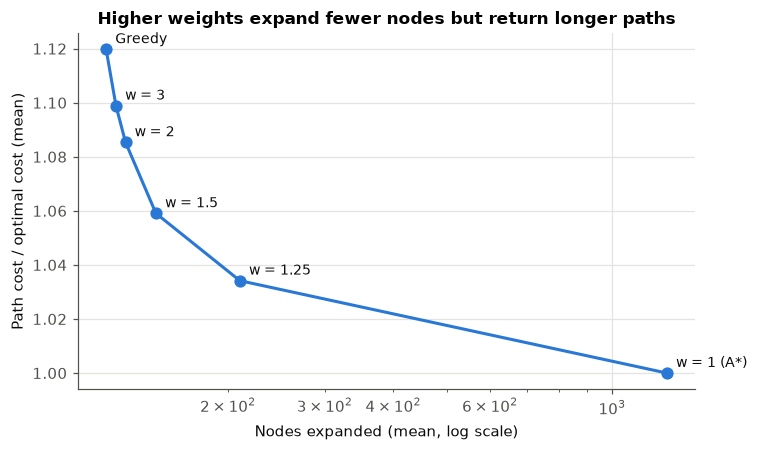

In [6]:
s4 = raw["sweep4_weight"]
t4 = summarise(s4, ["planner"])
order4 = ["astar_w1", "weighted_astar_w1.25", "weighted_astar_w1.5", "weighted_astar_w2", "weighted_astar_w3", "greedy"]
names4 = {"astar_w1": "w = 1 (A*)", "weighted_astar_w1.25": "w = 1.25", "weighted_astar_w1.5": "w = 1.5",
          "weighted_astar_w2": "w = 2", "weighted_astar_w3": "w = 3", "greedy": "Greedy"}
t4 = t4.loc[order4]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(t4[("expanded", "mean")], t4[("suboptimality_ratio", "mean")], color="#2a78d6", marker="o")
for planner, row in t4.iterrows():
    ax.annotate(names4[planner], (row[("expanded", "mean")], row[("suboptimality_ratio", "mean")]),
                xytext=(6, 4), textcoords="offset points", fontsize=9, color=INK)
ax.set_xscale("log")
ax.set_xlabel("Nodes expanded (mean, log scale)")
ax.set_ylabel("Path cost / optimal cost (mean)")
ax.set_title("Higher weights expand fewer nodes but return longer paths")
fig.tight_layout()
fig.savefig(FIGURES / "fig_sweep4_weight_tradeoff.png")
plt.show()

## Sweep 5: map type and terrain

/var/folders/1z/p8dptcb57h9_93kfys692jn80000gn/T/ipykernel_9073/3909987876.py:32: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  table["pairs"] = grouped.size()


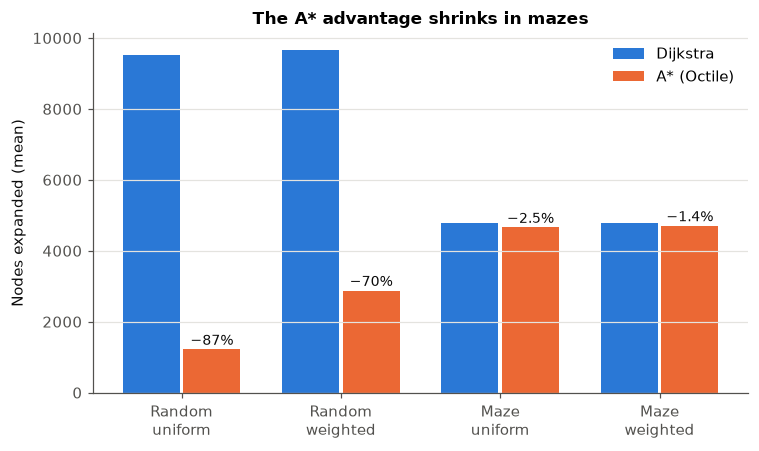

In [7]:
s5 = raw["sweep5_map_terrain"]
t5 = summarise(s5, ["map_type", "terrain", "planner"])
groups = [("random", "uniform"), ("random", "weighted"), ("maze", "uniform"), ("maze", "weighted")]
fig, ax = plt.subplots(figsize=(7, 4.2))
width = 0.38
for i, planner in enumerate(["dijkstra", "astar"]):
    means = [t5.loc[(m, t, planner), ("expanded", "mean")] for m, t in groups]
    xs = np.arange(len(groups)) + (i - 0.5) * width
    ax.bar(xs, means, width * 0.94, color=PLANNER_COLOUR[planner], label=PLANNER_LABEL[planner])
for k, (m, t) in enumerate(groups):
    d = t5.loc[(m, t, "dijkstra"), ("expanded", "mean")]
    a = t5.loc[(m, t, "astar"), ("expanded", "mean")]
    cut = (1 - a / d) * 100
    ax.annotate(f"−{cut:.0f}%" if cut >= 10 else f"−{cut:.1f}%", (k + width / 2, a), xytext=(0, 3), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
ax.set_xticks(range(len(groups)), [f"{m.capitalize()}\n{t}" for m, t in groups])
ax.set_ylabel("Nodes expanded (mean)")
ax.set_title("The A* advantage shrinks in mazes")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "fig_sweep5_map_terrain.png")
plt.show()

## Tables

In [8]:
base = t1.xs(128, level="grid_size").loc[list(PLANNER_LABEL)]
main_table = pd.DataFrame({
    "Planner": [PLANNER_LABEL[p] for p in base.index],
    "Nodes expanded": mean_std(base, "expanded", 0).values,
    "Runtime (ms)": mean_std(base, "runtime_ms", 2).values,
    "Path cost": mean_std(base, "path_cost", 1).values,
    "Cost / optimal": base[("suboptimality_ratio", "mean")].round(3).values,
    "Peak memory (nodes)": mean_std(base, "peak_memory", 0).values,
    "Pairs": base["pairs"].values,
})
main_table.to_csv(TABLES / "table_main_base_config.csv", index=False)
main_table

,Planner,Nodes expanded,Runtime (ms),Path cost,Cost / optimal,Peak memory (nodes),Pairs
0,Dijkstra,9574.0 ± 2354.0,52.17 ± 13.01,101.7 ± 20.1,1.000,9773.0 ± 2373.0,50
1,A* (Octile),1110.0 ± 684.0,7.22 ± 4.44,101.7 ± 20.1,1.000,1470.0 ± 762.0,50
2,Greedy Best-First,117.0 ± 26.0,0.78 ± 0.17,113.3 ± 21.3,1.118,289.0 ± 56.0,50
3,Weighted A* (w = 2),125.0 ± 31.0,0.83 ± 0.2,110.4 ± 21.2,1.087,299.0 ± 60.0,50


In [9]:
size_table = t1[("expanded", "mean")].unstack("planner")[list(PLANNER_LABEL)].round(0)
size_table.columns = [PLANNER_LABEL[c] for c in size_table.columns]
size_table["A* saving vs Dijkstra (%)"] = saving.round(1)
size_table["A* speed-up (x)"] = (speed["dijkstra"] / speed["astar"]).round(1)
size_table.to_csv(TABLES / "table_sweep1_by_size.csv")
size_table

,Dijkstra,A* (Octile),Greedy Best-First,Weighted A* (w = 2),A* saving vs Dijkstra (%),A* speed-up (x)
grid_size,,,,,,
32,578.0,94.0,31.0,34.0,83.8,5.1
64,2522.0,366.0,64.0,71.0,85.5,5.8
128,9574.0,1110.0,117.0,125.0,88.4,7.2
256,39171.0,4764.0,242.0,266.0,87.8,7.0
512,151060.0,19521.0,469.0,502.0,87.1,7.0


In [10]:
heur_table = pd.DataFrame({
    "Nodes expanded": mean_std(t3, "expanded", 0),
    "Cost / optimal": t3[("suboptimality_ratio", "mean")].round(3),
    "Worst cost / optimal": reachable(s3).groupby(["heuristic", "connectivity"]).suboptimality_ratio.max().round(3),
})
heur_table.to_csv(TABLES / "table_sweep3_heuristics.csv")
heur_table

Nodes expanded  Cost / optimal  Worst cost / optimal
heuristic connectivity                                                       
chebyshev 4             3764.0 ± 1835.0            1.00                 1.000
          8             2770.0 ± 1264.0            1.00                 1.000
euclidean 4             3287.0 ± 1690.0            1.00                 1.000
          8              1956.0 ± 965.0            1.00                 1.000
manhattan 4               793.0 ± 798.0            1.00                 1.000
          8               586.0 ± 566.0            1.04                 1.114
octile    4             2998.0 ± 1639.0            1.00                 1.000
          8              1309.0 ± 791.0            1.00                 1.000

In [11]:
weight_table = pd.DataFrame({
    "Nodes expanded": mean_std(t4, "expanded", 0),
    "Cost / optimal (mean)": t4[("suboptimality_ratio", "mean")].round(3),
    "Cost / optimal (worst)": reachable(s4).groupby("planner").suboptimality_ratio.max().loc[order4].round(3),
}).rename(index=names4)
weight_table.to_csv(TABLES / "table_sweep4_weights.csv")
weight_table

,Nodes expanded,Cost / optimal (mean),Cost / optimal (worst)
planner,,,
w = 1 (A*),1259.0 ± 764.0,1.000,1.000
w = 1.25,210.0 ± 163.0,1.034,1.085
w = 1.5,148.0 ± 65.0,1.059,1.118
w = 2,130.0 ± 29.0,1.085,1.184
w = 3,125.0 ± 29.0,1.099,1.290
Greedy,120.0 ± 23.0,1.120,1.315


## Headline numbers for sections a) and h)

In [12]:
w2 = t4.loc["weighted_astar_w2"]
a1 = t4.loc["astar_w1"]
maze = t5.loc[("maze", "uniform")]
largest, smallest = saving.index.max(), saving.index.min()
headline = {
    f"A* node saving vs Dijkstra, {largest}x{largest} (%)": round(saving.loc[largest], 1),
    f"A* speed-up vs Dijkstra, {largest}x{largest} (x)": round((speed["dijkstra"] / speed["astar"]).loc[largest], 1),
    f"A* node saving vs Dijkstra, {smallest}x{smallest} (%)": round(saving.loc[smallest], 1),
    "A* node saving vs Dijkstra, mean over sizes (%)": round(saving.mean(), 1),
    "Weighted A* w=2: node saving vs A* (%)": round((1 - w2[("expanded", "mean")] / a1[("expanded", "mean")]) * 100, 1),
    "Weighted A* w=2: mean cost above optimal (%)": round((w2[("suboptimality_ratio", "mean")] - 1) * 100, 1),
    "Weighted A* w=2: worst cost above optimal (%)": round((reachable(s4)[s4.planner == "weighted_astar_w2"].suboptimality_ratio.max() - 1) * 100, 1),
    "A* node saving vs Dijkstra, maze uniform (%)": round((1 - maze.loc["astar", ("expanded", "mean")] / maze.loc["dijkstra", ("expanded", "mean")]) * 100, 1),
    "A* node saving vs Dijkstra, random uniform (%)": round((1 - t5.loc[("random", "uniform", "astar"), ("expanded", "mean")] / t5.loc[("random", "uniform", "dijkstra"), ("expanded", "mean")]) * 100, 1),
}
pd.Series(headline, name="value").to_csv(TABLES / "headline_numbers.csv")
pd.Series(headline, name="value")

/var/folders/1z/p8dptcb57h9_93kfys692jn80000gn/T/ipykernel_9073/2636539319.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  "Weighted A* w=2: worst cost above optimal (%)": round((reachable(s4)[s4.planner == "weighted_astar_w2"].suboptimality_ratio.max() - 1) * 100, 1),


A* node saving vs Dijkstra, 512x512 (%)            87.1
A* speed-up vs Dijkstra, 512x512 (x)                7.0
A* node saving vs Dijkstra, 32x32 (%)              83.8
A* node saving vs Dijkstra, mean over sizes (%)    86.5
Weighted A* w=2: node saving vs A* (%)             89.7
Weighted A* w=2: mean cost above optimal (%)        8.5
Weighted A* w=2: worst cost above optimal (%)      18.4
A* node saving vs Dijkstra, maze uniform (%)        2.5
A* node saving vs Dijkstra, random uniform (%)     87.2
Name: value, dtype: float64